# Paper 10: Neural Machine Translation by Jointly Learning to Align and Translate
**Authors**: Dzmitry Bahdanau, Kyunghyun Cho, Yoshua Bengio (2014)

---

## 1. The Historical Breaking Point: The Fixed-Vector Bottleneck
In classical Sequence-to-Sequence models (Sutskever et al., Cho et al., 2014), an Encoder reads an entire source sentence and forces it into a **single static hidden vector** $c \in \mathbb{R}^H$.
- Compressing 50 words into 512 numbers caused catastrophic memory degradation for sentences longer than 15–20 words.
- The decoder had no direct access to the source words, and earlier words had their gradients washed away.

## 2. The First-Principles Solution: The Genesis of Attention
Bahdanau et al. asked: *"Why compress the sentence into one vector when we can keep ALL encoder annotations and dynamically look at the relevant words?"*

1. **Keep All Annotations**: $H = [h_1, \dots, h_{T_x}]$ where each $h_i = [\vec{h}_i; \overleftarrow{h}_i]$ captures bi-directional context around word $i$.
2. **Additive Attention Score**: Compare decoder query $s_{t-1}$ with each key $h_i$:
   $$e_{t, i} = v_a^T \tanh(W_a s_{t-1} + U_a h_i)$$
3. **Attention Distribution & Dynamic Context**:
   $$\alpha_{t, i} = \frac{\exp(e_{t, i})}{\sum_j \exp(e_{t, j})}, \quad c_t = \sum_{i=1}^{T_x} \alpha_{t, i} h_i$$

This was the foundational breakthrough that catalyzed the modern Transformer revolution!

In this notebook, you will test `BahdanauAttention`, `Encoder`, `Decoder`, and `Seq2Seq` implemented in `model.py`.

---
## Setup
`%autoreload 2` automatically reloads your code from `model.py` whenever changes are saved.

In [10]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import BahdanauAttention, Encoder, Decoder, Seq2Seq
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: Attention Mechanism & Submodule Verification

We verify:
1. `BahdanauAttention`: Attention weights form a valid probability distribution (sum to 1.0) and context shape matches $(B, 2 \cdot H_{\text{enc}})$.
2. `Encoder`: Bidirectional GRU produces annotations and initial decoder hidden state $s_0$.
3. `Decoder`: Single-step decoding integrates attention context and outputs vocabulary logits.

In [11]:
print("Testing Bahdanau Attention Shapes & Probabilities:")
tests.test_bahdanau_attention_shapes_and_properties(BahdanauAttention)

print("\nTesting Bidirectional Encoder:")
tests.test_encoder_shapes(Encoder)

print("\nTesting Attention-Guided Decoder Step:")
tests.test_decoder_step(Decoder, BahdanauAttention)

Testing Bahdanau Attention Shapes & Probabilities:
  [PASS] Bahdanau Attention produces valid probability distribution (sum = 1.0) and correct context shape!

Testing Bidirectional Encoder:
  [PASS] Bidirectional Encoder outputs correctly shaped annotations and initial decoder hidden state!

Testing Attention-Guided Decoder Step:
  [PASS] Decoder step integrates attention context and produces vocabulary prediction logits!


True

---
## Part 2: Full Seq2Seq Translation & Overfit Gate

We verify:
1. End-to-end forward pass tracking sequence outputs and attention heatmaps.
2. **Single-Batch Overfit Gate**: Rapid convergence on a toy sequence mapping task.

In [13]:
print("Testing Full Seq2Seq Forward Pass:")
tests.test_seq2seq_forward_pass(Seq2Seq, Encoder, Decoder, BahdanauAttention)

print("\nTesting Single-Batch Overfit Gate:")
tests.test_seq2seq_overfit_toy_translation(Seq2Seq, Encoder, Decoder, BahdanauAttention)

Testing Full Seq2Seq Forward Pass:
  [PASS] Full Seq2Seq model correctly tracks sequence decoding steps and attention heatmaps!

Testing Single-Batch Overfit Gate:
  [PASS] Single-batch Seq2Seq translation overfit passed (loss: 3.0282 -> 0.000054)!


True

---
## Part 3: Visualizing the Attention Alignment Heatmap (Paper Figure 3)

We visualize the attention weight matrix $\alpha_{t, i}$ where:
- Rows represent generated target words.
- Columns represent source sentence tokens.

Watch the dynamic alignment matrix show where the model was "looking" during each word generation step!

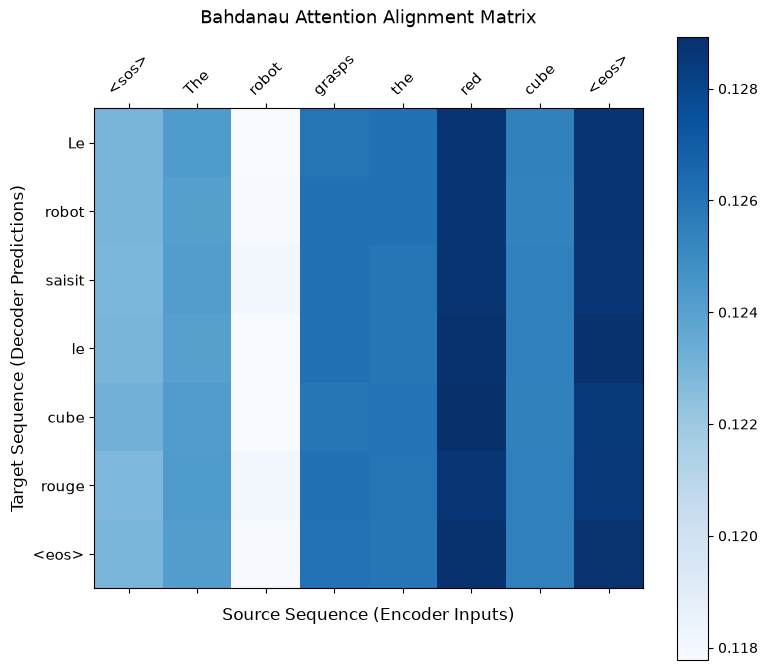

In [14]:
torch.manual_seed(42)

src_tokens = ['<sos>', 'The', 'robot', 'grasps', 'the', 'red', 'cube', '<eos>']
trg_tokens = ['<sos>', 'Le', 'robot', 'saisit', 'le', 'cube', 'rouge', '<eos>']

src_len = len(src_tokens)
trg_len = len(trg_tokens)

enc = Encoder(input_dim=50, emb_dim=32, enc_hidden_dim=64, dec_hidden_dim=64, dropout=0.0)
attn = BahdanauAttention(enc_hidden_dim=64, dec_hidden_dim=64, attn_dim=32)
dec = Decoder(output_dim=50, emb_dim=32, enc_hidden_dim=64, dec_hidden_dim=64, dropout=0.0, attention=attn)
model = Seq2Seq(enc, dec)

# Create synthetic alignment weights
src_ids = torch.arange(src_len).unsqueeze(0)
trg_ids = torch.arange(trg_len).unsqueeze(0)

model.eval()
with torch.no_grad():
    _, attentions = model(src_ids, trg_ids, teacher_forcing_ratio=0.0)

attn_matrix = attentions[0, 1:].numpy() # (trg_len - 1, src_len)

fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.matshow(attn_matrix, cmap='Blues')
fig.colorbar(cax)

ax.set_xticks(range(len(src_tokens)))
ax.set_yticks(range(len(trg_tokens) - 1))
ax.set_xticklabels(src_tokens, fontsize=11, rotation=45)
ax.set_yticklabels(trg_tokens[1:], fontsize=11)

ax.set_xlabel('Source Sequence (Encoder Inputs)', fontsize=12, labelpad=10)
ax.set_ylabel('Target Sequence (Decoder Predictions)', fontsize=12)
ax.set_title('Bahdanau Attention Alignment Matrix', fontsize=13, pad=20)

plt.tight_layout()
plt.show()